# Analisis 1 (obligatorio) - Curvas de salida por cohorte

**Hugo Tobias — analista de startups e industrias**

## La pregunta
Por **anio de primera ronda**, que porcentaje de empresas logro una **salida**
(adquisicion o IPO) dentro de **1, 3 y 5 anios**.

## El metodo en una frase
Agrupamos cada empresa por el anio de su primera ronda, miramos si salio antes
de cumplir 1, 3 o 5 anios desde esa ronda, y **sacamos del denominador a las que
todavia no han tenido tiempo de cumplir el plazo** dentro de los datos.

## Las cuatro decisiones que cambian el resultado
1. **La cohorte es el anio de la primera ronda, no el de fundacion.**
   `founded_at` esta vacia en el 54% de las empresas (bitacora de calidad, fila 2).
2. **Exito = adquisicion o IPO, sin exigir monto.** 7,085 de 9,561 adquisiciones
   no reportan precio en USD (bitacora, fila 12). Mas abajo medimos que pasa si
   se exige.
3. **Las cohortes sin plazo cumplido no se cuentan como fracaso.** Los datos
   cortan el 2013-12-31. Una empresa que levanto su primera ronda en 2012
   todavia no completa 3 anios de observacion: que no se le vea salida no
   significa que fracaso (*censura por la derecha*).
4. **Solo se leen las cohortes de 2005 en adelante.** Esta es la decision que
   mas cuesta y la que mas defiende el analisis. Crunchbase casi no tiene datos
   antes de 2005: la cohorte de 1999 tiene **53 empresas** y la de 2004 tiene
   **204**, contra **1,437 en 2005** y **5,850 en 2013**. Una tasa calculada
   sobre 53 empresas se mueve dos puntos porcentuales cuando cambia **una sola**.
   Las cohortes chicas se calculan y se publican en la tabla, pero no se grafican
   ni se citan.

> **Analogia:** es como medir cuantos alumnos de cada generacion se graduaron en
> 5 anios. A la generacion que entro hace 2 anios no se le puede decir "no se
> graduo": todavia no le toca (punto 3). Y de las generaciones viejas solo
> quedan los expedientes de cinco alumnos, asi que su porcentaje no dice nada
> del colegio (punto 4).

In [1]:
# --- Conexion al pipeline del proyecto -------------------------------------
# Funciona lo mismo si abres el notebook desde notebooks/ o desde la raiz:
# busca hacia arriba la carpeta que tiene run_all.py.
import pathlib, warnings
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

def raiz_proyecto() -> pathlib.Path:
    p = pathlib.Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "run_all.py").exists():
            return c
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto (la carpeta con run_all.py). "
        "Abre el notebook dentro del repo clonado.")

RAIZ = raiz_proyecto()
DB = RAIZ / "data" / "crunchbase.duckdb"
if not DB.exists():
    raise FileNotFoundError(
        f"No existe {DB}. Corre primero, desde la raiz del repo:\n"
        f"    python run_all.py")

con = duckdb.connect(str(DB))          # lectura y escritura: al final guardamos resultados
CORTE = pd.Timestamp("2013-12-31")     # los datos de Crunchbase terminan aqui
print("Proyecto:", RAIZ)
print("Base    :", DB)

def existe(esquema, tabla) -> bool:
    return con.execute(
        "SELECT COUNT(*) FROM information_schema.tables "
        "WHERE table_schema = ? AND table_name = ?", [esquema, tabla]).fetchone()[0] > 0

def exigir(*tablas):
    """Falla ruidosamente si falta un insumo, en vez de dar resultados vacios."""
    faltan = [f"{e}.{t}" for e, t in tablas if not existe(e, t)]
    if faltan:
        raise RuntimeError(
            "Faltan tablas del modelo: " + ", ".join(faltan) +
            ".\nCorre `python run_all.py` desde la raiz (incluye los .sql de la rama hugo/fred).")
    for e, t in tablas:
        n = con.execute(f"SELECT COUNT(*) FROM {e}.{t}").fetchone()[0]
        print(f"  {e}.{t}: {n:,} filas")
        if n == 0:
            raise RuntimeError(f"{e}.{t} existe pero esta vacia. No se puede analizar.")

Proyecto: /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final
Base    : /Users/robertomejia/Proyectos/crunchbase-bi-proyecto-final/data/crunchbase.duckdb


In [2]:
# --- Verificacion de insumos -----------------------------------------------
exigir(("marts", "dim_empresa"), ("marts", "fact_rondas"),
       ("marts", "fact_adquisiciones"), ("marts", "fact_ipos"),
       ("marts", "met_salida_empresa"), ("marts", "res_curvas_salida"))

maxs = con.execute("""
    SELECT MAX(fecha) FROM marts.fact_rondas
    UNION ALL SELECT MAX(fecha) FROM marts.fact_adquisiciones
    UNION ALL SELECT MAX(fecha) FROM marts.fact_ipos
""").fetchall()
print("Fechas maximas (rondas, adquisiciones, ipos):", [m[0] for m in maxs])
assert all(m[0] is None or pd.Timestamp(m[0]) <= CORTE for m in maxs), \
    "Hay eventos despues de 2013-12-31: revisar sql/03_clean/12_clean_fechas.sql"

MIN_COHORTE = 500   # empresas observables minimas para graficar una cohorte

  marts.dim_empresa: 197,560 filas
  marts.fact_rondas: 52,928 filas
  marts.fact_adquisiciones: 9,561 filas
  marts.fact_ipos: 1,254 filas
  marts.met_salida_empresa: 197,560 filas
  marts.res_curvas_salida: 90 filas
Fechas maximas (rondas, adquisiciones, ipos): [datetime.date(2013, 12, 12), datetime.date(2013, 12, 12), datetime.date(2013, 12, 11)]


## 1 · Cuantas empresas y cuantas salidas hay

Los numeros crudos antes de cualquier tasa. Si estos no cuadran con la bitacora,
no sirve nada de lo que venga despues.

In [3]:
resumen = con.execute("""
    SELECT
        COUNT(*)                                             AS empresas,
        COUNT(fecha_primera_ronda)                           AS con_al_menos_una_ronda,
        SUM(CASE WHEN tuvo_salida           THEN 1 ELSE 0 END) AS con_salida,
        SUM(CASE WHEN tuvo_salida_con_monto THEN 1 ELSE 0 END) AS con_salida_y_monto,
        SUM(CASE WHEN tipo_primera_salida = 'adquisicion' THEN 1 ELSE 0 END) AS primera_adquisicion,
        SUM(CASE WHEN tipo_primera_salida = 'ipo'         THEN 1 ELSE 0 END) AS primera_ipo
    FROM marts.met_salida_empresa
""").df()
display(resumen.T.rename(columns={0: "empresas"}))

con_ronda_y_salida = con.execute("""
    SELECT SUM(CASE WHEN tuvo_salida THEN 1 ELSE 0 END)
    FROM marts.met_salida_empresa WHERE fecha_primera_ronda IS NOT NULL
""").fetchone()[0]
print(f"\nSalidas en empresas CON ronda registrada: {con_ronda_y_salida:,}")
print(f"Salidas totales en la base:                {int(resumen.con_salida[0]):,}")
print("\nLa diferencia son empresas que Crunchbase registra como adquiridas o")
print("cotizadas SIN tener ninguna ronda registrada. Dice mas de la cobertura de")
print("la base que del mercado, y entra en docs/limitaciones.md.")

,empresas
empresas,197560.0
con_al_menos_una_ronda,31735.0
con_salida,9991.0
con_salida_y_monto,2569.0
primera_adquisicion,9344.0
primera_ipo,647.0



Salidas en empresas CON ronda registrada: 2,881
Salidas totales en la base:                9,991

La diferencia son empresas que Crunchbase registra como adquiridas o
cotizadas SIN tener ninguna ronda registrada. Dice mas de la cobertura de
la base que del mercado, y entra en docs/limitaciones.md.


## 2 · Por que solo se leen las cohortes de 2005 en adelante

Esta tabla es la justificacion. No es una opinion sobre que anios "se ven raros":
es el conteo de empresas por cohorte.

cohorte,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
empresas_cohorte,24,53,95,65,81,106,204,1437,1873,2205,2381,2481,3856,5574,5407,5850
se_grafica,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True,True


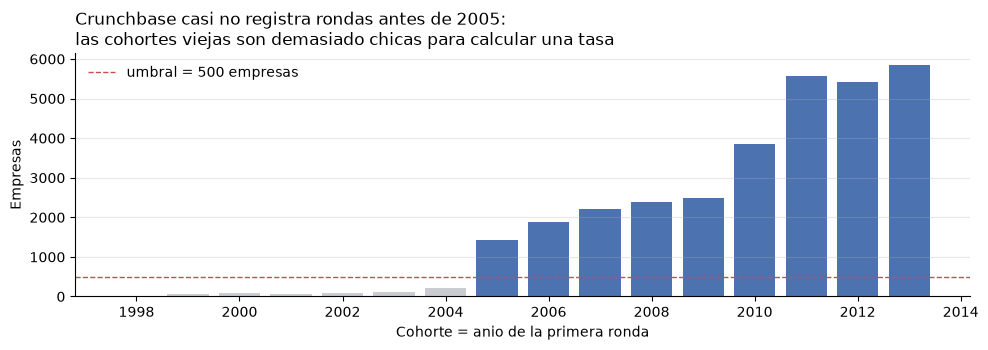

In [4]:
tam = con.execute("""
    SELECT cohorte, empresas_cohorte
    FROM marts.res_curvas_salida WHERE horizonte_anios = 1 AND cohorte >= 1998
    ORDER BY cohorte
""").df()
tam["se_grafica"] = tam.empresas_cohorte >= MIN_COHORTE
display(tam.set_index("cohorte").T)

fig, ax = plt.subplots(figsize=(10, 3.6))
colores = ["#4c72b0" if g else "#c9ccd1" for g in tam.se_grafica]
ax.bar(tam.cohorte, tam.empresas_cohorte, color=colores)
ax.axhline(MIN_COHORTE, color="#c44e52", ls="--", lw=1,
           label=f"umbral = {MIN_COHORTE} empresas")
ax.set_title("Crunchbase casi no registra rondas antes de 2005:\n"
             "las cohortes viejas son demasiado chicas para calcular una tasa",
             loc="left", fontsize=12)
ax.set_xlabel("Cohorte = anio de la primera ronda"); ax.set_ylabel("Empresas")
ax.legend(frameon=False); ax.grid(axis="y", alpha=.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3 · Las curvas de salida

`marts.res_curvas_salida` ya trae el calculo (`sql/04_marts/11_res_curvas_salida.sql`).

- `empresas_observables`: las que alcanzaron a cumplir el plazo antes de 2013-12-31.
- `cohorte_completa`: TRUE solo si **toda** la cohorte cumplio el plazo (`cohorte + H <= 2013`).

In [5]:
curvas = con.execute("SELECT * FROM marts.res_curvas_salida ORDER BY cohorte, horizonte_anios").df()
curvas["tasa_pct"] = (curvas.tasa_salida * 100).round(1)

legibles = curvas[curvas.cohorte_completa & (curvas.empresas_observables >= MIN_COHORTE)]
print("Cohortes que SI se pueden citar (completas y con suficientes empresas):")
display(legibles.pivot(index="cohorte", columns="horizonte_anios", values="tasa_pct")
        .rename(columns=lambda h: f"{h} anio(s) %"))

print("\nCohortes descartadas, y por que:")
desc = curvas[~(curvas.cohorte_completa & (curvas.empresas_observables >= MIN_COHORTE))].copy()
desc["motivo"] = np.where(~desc.cohorte_completa, "plazo sin cumplir", "cohorte muy chica")
display(desc[desc.cohorte >= 2000][["cohorte", "horizonte_anios", "empresas_cohorte",
                                    "empresas_observables", "tasa_pct", "motivo"]].head(20))

Cohortes que SI se pueden citar (completas y con suficientes empresas):


horizonte_anios,1 anio(s) %,3 anio(s) %,5 anio(s) %
cohorte,,,
2005,1.3,7.9,17.6
2006,1.6,8.1,16.4
2007,1.6,7.5,15.3
2008,1.0,6.6,11.0
2009,2.1,8.0,NaN
2010,2.5,7.3,NaN
2011,1.8,NaN,NaN
2012,1.5,NaN,NaN



Cohortes descartadas, y por que:


,cohorte,horizonte_anios,empresas_cohorte,empresas_observables,tasa_pct,motivo
48,2000,1,95,95.0,1.1,cohorte muy chica
49,2000,3,95,95.0,2.1,cohorte muy chica
50,2000,5,95,95.0,6.3,cohorte muy chica
51,2001,1,65,65.0,1.5,cohorte muy chica
52,2001,3,65,65.0,6.2,cohorte muy chica
53,2001,5,65,65.0,10.8,cohorte muy chica
54,2002,1,81,81.0,1.2,cohorte muy chica
55,2002,3,81,81.0,2.5,cohorte muy chica
56,2002,5,81,81.0,6.2,cohorte muy chica
57,2003,1,106,106.0,0.0,cohorte muy chica


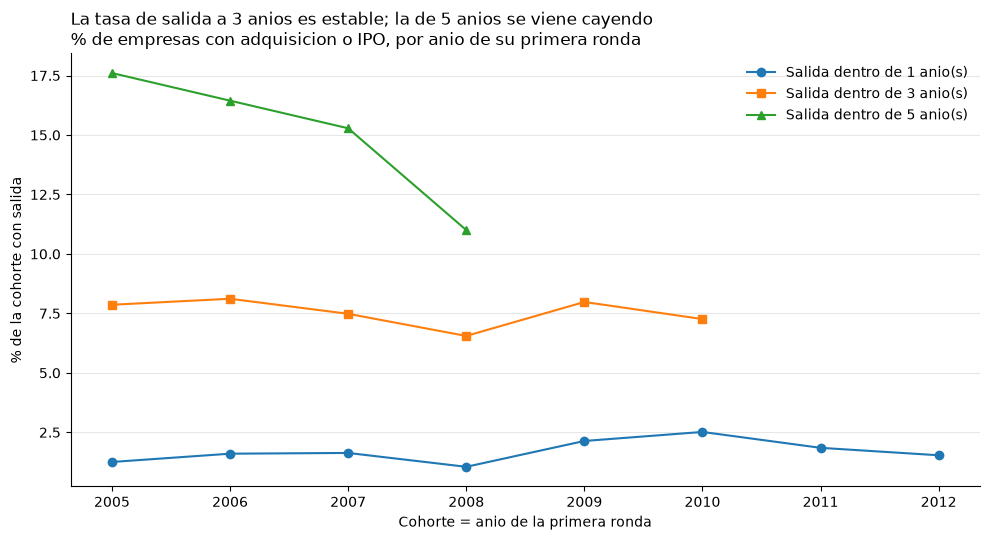

1 anio(s): cohortes 2005-2012, de 1.3% a 1.5%
3 anio(s): cohortes 2005-2010, de 7.9% a 7.3%
5 anio(s): cohortes 2005-2008, de 17.6% a 11.0%


In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for h, estilo in [(1, "o-"), (3, "s-"), (5, "^-")]:
    d_ = legibles[legibles.horizonte_anios == h].dropna(subset=["tasa_salida"])
    ax.plot(d_.cohorte, d_.tasa_salida * 100, estilo, label=f"Salida dentro de {h} anio(s)")

ax.set_title("La tasa de salida a 3 anios es estable; la de 5 anios se viene cayendo\n"
             "% de empresas con adquisicion o IPO, por anio de su primera ronda",
             loc="left", fontsize=12)
ax.set_xlabel("Cohorte = anio de la primera ronda")
ax.set_ylabel("% de la cohorte con salida")
ax.legend(frameon=False); ax.grid(axis="y", alpha=.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

for h in (1, 3, 5):
    d_ = legibles[legibles.horizonte_anios == h].dropna(subset=["tasa_salida"])
    if len(d_):
        print(f"{h} anio(s): cohortes {int(d_.cohorte.min())}-{int(d_.cohorte.max())}, "
              f"de {d_.tasa_pct.iloc[0]}% a {d_.tasa_pct.iloc[-1]}%")

## 4 · Que pasa si contamos mal las cohortes recientes

Recalculamos las mismas tasas **sin** sacar del denominador a las empresas sin
plazo cumplido (o sea, tratando "todavia no le toca" como "fracaso") y
comparamos. Esto demuestra que la decision 3 no es un tecnicismo.

In [7]:
ingenuo = con.execute("""
    WITH h(horizonte_anios) AS (SELECT * FROM (VALUES (1), (3), (5))),
    b AS (SELECT cohorte_primera_ronda AS cohorte, fecha_primera_ronda, fecha_primera_salida
          FROM marts.met_salida_empresa WHERE fecha_primera_ronda IS NOT NULL)
    SELECT b.cohorte, h.horizonte_anios,
           AVG(CASE WHEN b.fecha_primera_salida IS NOT NULL
                     AND b.fecha_primera_salida <= b.fecha_primera_ronda + to_years(h.horizonte_anios)
                    THEN 1.0 ELSE 0.0 END) AS tasa_ingenua
    FROM b CROSS JOIN h GROUP BY 1, 2
""").df()

cmp = (curvas.merge(ingenuo, on=["cohorte", "horizonte_anios"])
             .query("horizonte_anios == 3 and cohorte >= 2005")
             [["cohorte", "cohorte_completa", "empresas_cohorte", "empresas_observables",
               "tasa_salida", "tasa_ingenua"]].copy())
cmp["tasa_correcta_%"] = (cmp.tasa_salida * 100).round(1)
cmp["tasa_ingenua_%"]  = (cmp.tasa_ingenua * 100).round(1)
display(cmp[["cohorte", "cohorte_completa", "empresas_cohorte", "empresas_observables",
             "tasa_correcta_%", "tasa_ingenua_%"]])
print("Horizonte de 3 anios. En 2011-2013 la version ingenua se desploma sola,")
print("no porque las startups empeoraran, sino porque el reloj todavia corre.")

,cohorte,cohorte_completa,empresas_cohorte,empresas_observables,tasa_correcta_%,tasa_ingenua_%
64,2005,True,1437,1437.0,7.9,7.9
67,2006,True,1873,1873.0,8.1,8.1
70,2007,True,2205,2205.0,7.5,7.5
73,2008,True,2381,2381.0,6.6,6.6
76,2009,True,2481,2481.0,8.0,8.0
79,2010,True,3856,3856.0,7.3,7.3
82,2011,False,5574,0.0,NaN,5.0
85,2012,False,5407,0.0,NaN,2.5
88,2013,False,5850,0.0,NaN,1.2


Horizonte de 3 anios. En 2011-2013 la version ingenua se desploma sola,
no porque las startups empeoraran, sino porque el reloj todavia corre.


## 5 · Tiempo a la salida

Se mide **desde la primera ronda**, y solo entran las empresas que **si**
salieron: el tiempo a la salida de las que no han salido no existe todavia, no
es infinito. Por eso el numero esta **sesgado hacia abajo** y se publica junto
al conteo de censuradas.

In [8]:
t = con.execute("""
    SELECT cohorte_primera_ronda AS cohorte, anios_a_salida_desde_ronda AS anios,
           tipo_primera_salida, censurada
    FROM marts.met_salida_empresa WHERE fecha_primera_ronda IS NOT NULL
""").df()
salieron = t[t.anios.notna()]
print(f"Salieron: {len(salieron):,} | censuradas (sin salida al corte): {int(t.censurada.sum()):,}")
print(f"Mediana de anios a la salida: {salieron.anios.median():.2f}")
print(f"Cuartiles (p25 / p75): {salieron.anios.quantile(.25):.2f} / {salieron.anios.quantile(.75):.2f}")
print("\nPor tipo de salida:")
display(salieron.groupby("tipo_primera_salida").anios
        .agg(n="size", mediana="median", p25=lambda s: s.quantile(.25),
             p75=lambda s: s.quantile(.75)).round(2))

res_tiempo = (salieron.groupby("cohorte").anios
              .agg(salidas="size", mediana_anios="median",
                   p25_anios=lambda s: s.quantile(.25), p75_anios=lambda s: s.quantile(.75))
              .reset_index())
res_tiempo = res_tiempo.merge(
    t.groupby("cohorte").censurada.sum().rename("empresas_censuradas").reset_index(), on="cohorte")
display(res_tiempo[res_tiempo.cohorte >= 2005].round(2))
print("\nOjo con la tendencia: la mediana baja en las cohortes recientes POR CONSTRUCCION.")
print("Una empresa de 2011 no puede tener una salida a 6 anios dentro de estos datos,")
print("asi que solo se le ven las salidas rapidas. No es que salgan mas rapido.")

Salieron: 2,881 | censuradas (sin salida al corte): 28,854
Mediana de anios a la salida: 2.69
Cuartiles (p25 / p75): 1.37 / 4.50

Por tipo de salida:


,n,mediana,p25,p75
tipo_primera_salida,,,,
adquisicion,2565,2.76,1.49,4.49
ipo,316,1.32,-3.60,4.69


,cohorte,salidas,mediana_anios,p25_anios,p75_anios,empresas_censuradas
12,2005,431,4.44,2.92,6.02,1006
13,2006,436,3.99,2.31,5.27,1437
14,2007,406,3.47,2.27,4.54,1799
15,2008,287,2.83,1.88,4.09,2094
16,2009,272,2.09,1.24,3.17,2209
17,2010,328,1.61,0.86,2.62,3528
18,2011,279,1.38,0.58,1.98,5295
19,2012,135,0.77,0.02,1.21,5272
20,2013,69,-2.13,-5.35,-0.02,5781



Ojo con la tendencia: la mediana baja en las cohortes recientes POR CONSTRUCCION.
Una empresa de 2011 no puede tener una salida a 6 anios dentro de estos datos,
asi que solo se le ven las salidas rapidas. No es que salgan mas rapido.


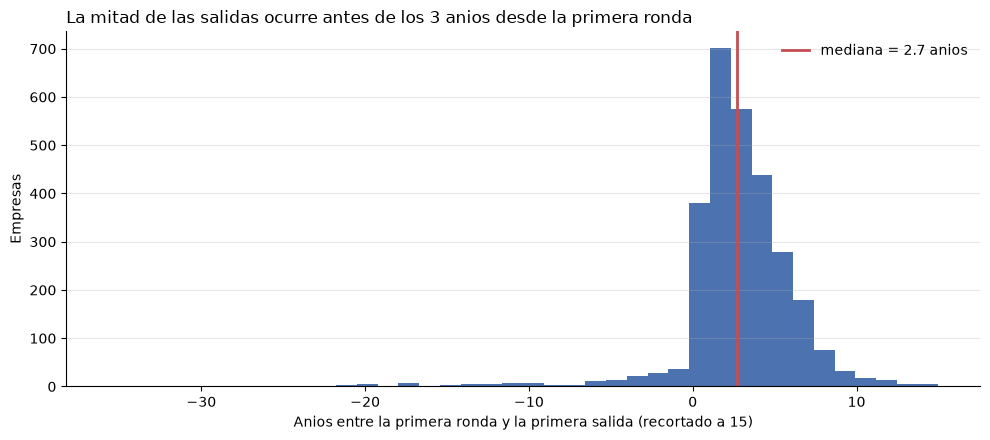

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(salieron.anios.clip(upper=15), bins=40, color="#4c72b0")
ax.axvline(salieron.anios.median(), color="#c44e52", lw=2,
           label=f"mediana = {salieron.anios.median():.1f} anios")
ax.set_title("La mitad de las salidas ocurre antes de los 3 anios desde la primera ronda",
             loc="left", fontsize=12)
ax.set_xlabel("Anios entre la primera ronda y la primera salida (recortado a 15)")
ax.set_ylabel("Empresas")
ax.legend(frameon=False); ax.grid(axis="y", alpha=.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6 · Sensibilidad: y si "exito" exigiera monto conocido?

Es la respuesta directa a la pregunta que el PDF anticipa para la defensa oral:
*"como cambiaria su conclusion con otra definicion de exito?"*

In [10]:
sens = con.execute("""
    WITH h(horizonte_anios) AS (SELECT * FROM (VALUES (1), (3), (5))),
    b AS (SELECT cohorte_primera_ronda AS cohorte, fecha_primera_ronda,
                 fecha_primera_salida, tuvo_salida_con_monto
          FROM marts.met_salida_empresa WHERE fecha_primera_ronda IS NOT NULL)
    SELECT h.horizonte_anios,
           SUM(CASE WHEN b.fecha_primera_ronda + to_years(h.horizonte_anios) <= DATE '2013-12-31'
                    THEN 1 ELSE 0 END) AS observables,
           AVG(CASE WHEN b.fecha_primera_ronda + to_years(h.horizonte_anios) <= DATE '2013-12-31'
                    THEN CASE WHEN b.fecha_primera_salida IS NOT NULL
                               AND b.fecha_primera_salida <= b.fecha_primera_ronda + to_years(h.horizonte_anios)
                              THEN 1.0 ELSE 0.0 END END) AS tasa_v1_cualquier_salida,
           AVG(CASE WHEN b.fecha_primera_ronda + to_years(h.horizonte_anios) <= DATE '2013-12-31'
                    THEN CASE WHEN b.tuvo_salida_con_monto
                               AND b.fecha_primera_salida <= b.fecha_primera_ronda + to_years(h.horizonte_anios)
                              THEN 1.0 ELSE 0.0 END END) AS tasa_v2_salida_con_monto
    FROM b CROSS JOIN h GROUP BY 1 ORDER BY 1
""").df()
sens["tasa_v1_%"] = (sens.tasa_v1_cualquier_salida * 100).round(2)
sens["tasa_v2_%"] = (sens.tasa_v2_salida_con_monto * 100).round(2)
sens["queda_en"]  = (sens.tasa_v2_salida_con_monto / sens.tasa_v1_cualquier_salida).round(2)
display(sens[["horizonte_anios", "observables", "tasa_v1_%", "tasa_v2_%", "queda_en"]])
print("`queda_en` = que fraccion de la tasa sobrevive al exigir monto conocido.")
print("Exigir monto no cambia la FORMA de las curvas, solo su nivel: el ranking")
print("entre cohortes se mantiene. Esa es la respuesta corta en la defensa.")

,horizonte_anios,observables,tasa_v1_%,tasa_v2_%,queda_en
0,1,25885.0,1.75,0.41,0.24
1,3,14904.0,7.35,2.12,0.29
2,5,8567.0,14.36,4.68,0.33


`queda_en` = que fraccion de la tasa sobrevive al exigir monto conocido.
Exigir monto no cambia la FORMA de las curvas, solo su nivel: el ranking
entre cohortes se mantiene. Esa es la respuesta corta en la defensa.


## 7 · Guardar resultados como tablas (no como archivos sueltos)

In [11]:
con.execute("CREATE SCHEMA IF NOT EXISTS marts")
con.register("tmp_tiempo", res_tiempo)
con.execute("CREATE OR REPLACE TABLE marts.res_tiempo_salida_cohorte AS SELECT * FROM tmp_tiempo")
con.register("tmp_sens", sens.drop(columns=["tasa_v1_%", "tasa_v2_%"]))
con.execute("CREATE OR REPLACE TABLE marts.res_sensibilidad_exito AS SELECT * FROM tmp_sens")
con.register("tmp_tam", tam)
con.execute("CREATE OR REPLACE TABLE marts.res_cobertura_cohortes AS SELECT * FROM tmp_tam")

for t_ in ("res_curvas_salida", "res_tiempo_salida_cohorte",
           "res_sensibilidad_exito", "res_cobertura_cohortes"):
    print(f"marts.{t_}: {con.execute(f'SELECT COUNT(*) FROM marts.{t_}').fetchone()[0]:,} filas")
con.close()
print("\nOrden para reproducir: python run_all.py -> notebooks -> python publish/publish_to_neon.py")

marts.res_curvas_salida: 90 filas
marts.res_tiempo_salida_cohorte: 21 filas
marts.res_sensibilidad_exito: 3 filas
marts.res_cobertura_cohortes: 16 filas

Orden para reproducir: python run_all.py -> notebooks -> python publish/publish_to_neon.py


## Resultado, interpretacion y advertencia

**Resultado.** Sobre las cohortes legibles (2005 en adelante, cada una con mas de
mil empresas), la tasa de salida a **3 anios se mantiene entre 6.6% y 8.1%** en
todas las cohortes de 2005 a 2010, mientras que la tasa a **5 anios cae de 17.6%
(cohorte 2005) a 11.0% (cohorte 2008)**. La mediana de tiempo a la salida es de
**2.7 anios** (cuartiles 1.4 y 4.5), calculada sobre las 2,881 empresas que
salieron, contra 28,854 que al corte de 2013 seguian sin salir. Exigir que la
salida traiga monto conocido en USD baja el nivel de las tasas pero **no cambia
el orden entre cohortes**.

**Interpretacion (dos frases).** Lo que cambia entre cohortes no es la
probabilidad de una salida rapida —esa es notablemente estable, alrededor de uno
de cada trece a tres anios— sino la cola larga: las cohortes mas recientes
acumulan menos salidas entre el tercer y el quinto anio. Para el comite eso
significa que el plazo de salida se esta alargando mas que lo que esta cayendo
la probabilidad de salir, y que un fondo con horizonte de cinco anios deberia
revisar ese supuesto.

**Advertencia: lo que esto NO demuestra.**
1. **La caida de la tasa a 5 anios puede ser el borde de los datos.** Solo hay
   cuatro cohortes legibles con horizonte de 5 anios (2005-2008), y la de 2008
   cierra su ventana exactamente en 2013-12-31. Con una sola cohorte mas la
   conclusion podria moverse.
2. **No dice nada sobre antes de 2005.** No porque el mercado no existiera, sino
   porque Crunchbase no lo registro: la cohorte de 1999 tiene 53 empresas.
3. **"Salida" no es rentabilidad.** Una adquisicion de rescate cuenta igual que
   una exitosa, y en tres de cada cuatro casos ni siquiera sabemos el precio.
4. **La mediana de 2.7 anios esta sesgada hacia abajo**, porque las salidas
   lentas de las cohortes recientes todavia no ocurren.